# Flight Delay Prediction — Phase 1 (Machine Learning)

**Project 21:** Flight Delay Prediction via Gradient Boosting and Temporal Deep Learning

**Goal:** predict whether a flight will **arrive 15 or more minutes late**, using only information that is known
**before the flight departs**.

**Dataset:** Flights 2013 (`nycflights13`) — every flight that left a New York City airport (JFK, LGA, EWR) in 2013.

**Models (Phase 1):** Logistic Regression (baseline) and XGBoost.

### Contents
1. Load the data
2. Data quality checks
3. Exploratory Data Analysis (EDA)
4. Removing data leakage
5. Feature engineering
6. Train / validation / test split by date
7. Models: Logistic Regression and XGBoost
8. Evaluation and calibration
9. Conclusion

In [1]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nycflights13 import flights

sns.set_style("whitegrid")
os.makedirs("figures", exist_ok=True)
RANDOM_STATE = 42

## 1. Load the data

Each row is one scheduled flight. The `flights` table has 19 columns: the date, scheduled and actual departure/arrival
times, the delays, carrier, flight number, plane tail number, origin, destination, air time and distance.

In [2]:
df = flights.copy()
print("Shape:", df.shape)
df.head()

Shape: (336776, 19)


,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,carrier,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour
0,2013,1,1,517.0,515,2.0,830.0,819,11.0,UA,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01T10:00:00Z
1,2013,1,1,533.0,529,4.0,850.0,830,20.0,UA,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01T10:00:00Z
2,2013,1,1,542.0,540,2.0,923.0,850,33.0,AA,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01T10:00:00Z
3,2013,1,1,544.0,545,-1.0,1004.0,1022,-18.0,B6,725,N804JB,JFK,BQN,183.0,1576,5,45,2013-01-01T10:00:00Z
4,2013,1,1,554.0,600,-6.0,812.0,837,-25.0,DL,461,N668DN,LGA,ATL,116.0,762,6,0,2013-01-01T11:00:00Z


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 336776 entries, 0 to 336775
Data columns (total 19 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   year            336776 non-null  int64  
 1   month           336776 non-null  int64  
 2   day             336776 non-null  int64  
 3   dep_time        328521 non-null  float64
 4   sched_dep_time  336776 non-null  int64  
 5   dep_delay       328521 non-null  float64
 6   arr_time        328063 non-null  float64
 7   sched_arr_time  336776 non-null  int64  
 8   arr_delay       327346 non-null  float64
 9   carrier         336776 non-null  str    
 10  flight          336776 non-null  int64  
 11  tailnum         334264 non-null  str    
 12  origin          336776 non-null  str    
 13  dest            336776 non-null  str    
 14  air_time        327346 non-null  float64
 15  distance        336776 non-null  int64  
 16  hour            336776 non-null  int64  
 17  minute          33677

## 2. Data quality checks

We check for missing values and duplicate rows.

In [4]:
missing = df.isna().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())

dep_time     8255
dep_delay    8255
arr_time     8713
arr_delay    9430
tailnum      2512
air_time     9430
dtype: int64

Duplicate rows: 0


- About 8,255 flights have no `dep_time` — these flights were **cancelled**.
- About 9,430 flights have no `arr_delay` — cancelled flights plus a few **diverted** flights that never arrived at the planned destination.
- There are no duplicate rows.

Our target needs the arrival delay, so we **drop flights without an `arr_delay`** (cancelled/diverted flights are a
different problem). Missing `tailnum` values do not matter because we do not use that column.

In [5]:
df = df.dropna(subset=["arr_delay"]).copy()

# Target: 1 if the flight arrived 15+ minutes late (the US Department of Transportation definition of "delayed")
df["delayed"] = (df["arr_delay"] >= 15).astype(int)

# A proper date column, used for EDA, features and the date-based split
df["date"] = pd.to_datetime(df[["year", "month", "day"]])

print("Flights left:", len(df))
print("Delayed share:", round(df["delayed"].mean(), 3))

Flights left: 327346
Delayed share: 0.245


## 3. Exploratory Data Analysis

### 3.1 Target balance and the distribution of arrival delays

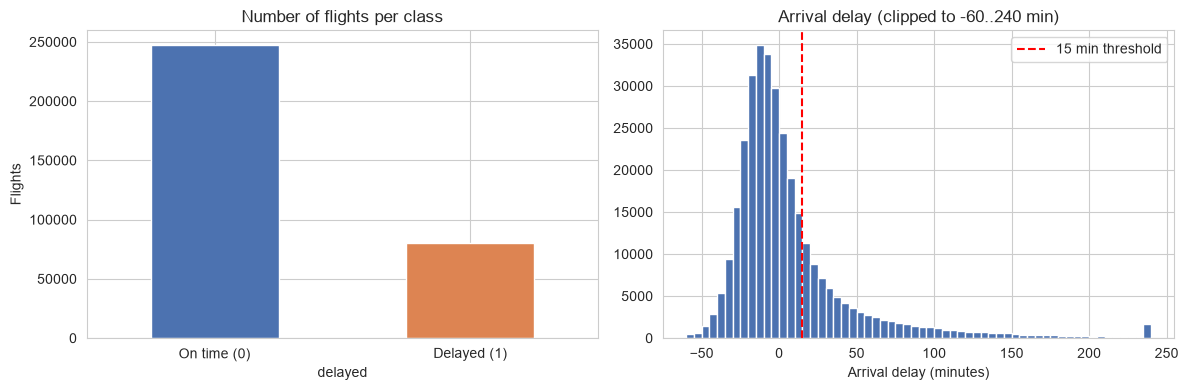

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df["delayed"].value_counts().sort_index().plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452"])
axes[0].set_xticks([0, 1], ["On time (0)", "Delayed (1)"], rotation=0)
axes[0].set_title("Number of flights per class")
axes[0].set_ylabel("Flights")

axes[1].hist(df["arr_delay"].clip(-60, 240), bins=60, color="#4C72B0")
axes[1].axvline(15, color="red", linestyle="--", label="15 min threshold")
axes[1].set_title("Arrival delay (clipped to -60..240 min)")
axes[1].set_xlabel("Arrival delay (minutes)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/target_distribution.png", dpi=150)
plt.show()

- Only about **1 in 4 flights is delayed**, so the classes are **imbalanced**. Accuracy would be misleading
  (always predicting "on time" already gives ~75%), so we use PR AUC and ROC AUC later.
- Most flights arrive early or on time; delays have a **long right tail** (a few flights are hours late).

### 3.2 Delay rate by month, weekday and hour

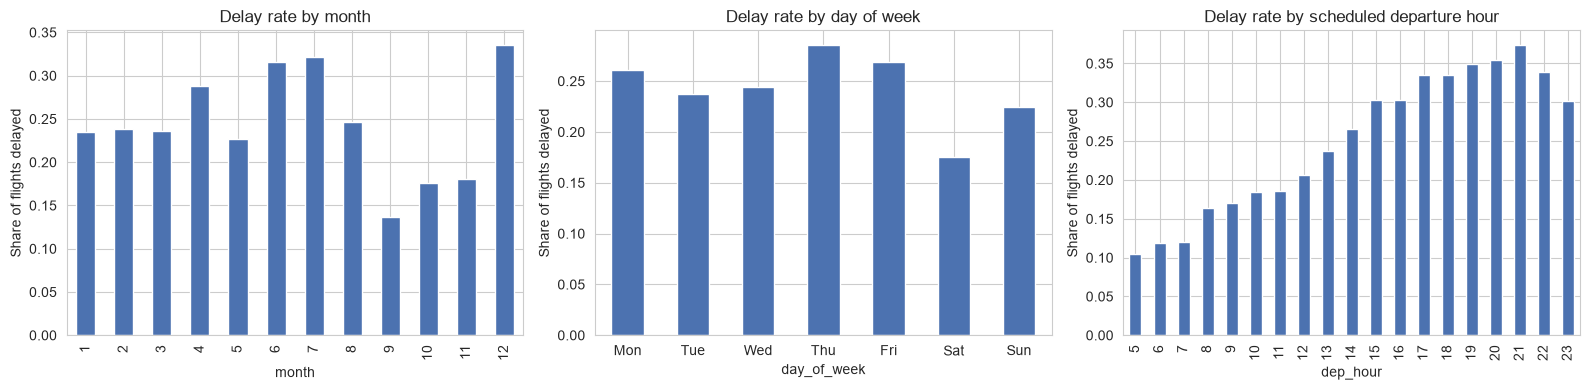

In [7]:
df["day_of_week"] = df["date"].dt.dayofweek   # 0 = Monday
df["dep_hour"] = df["sched_dep_time"] // 100

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("month")["delayed"].mean().plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by month")
df.groupby("day_of_week")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
axes[1].set_title("Delay rate by day of week")
df.groupby("dep_hour")["delayed"].mean().plot(kind="bar", ax=axes[2], color="#4C72B0")
axes[2].set_title("Delay rate by scheduled departure hour")
for ax in axes:
    ax.set_ylabel("Share of flights delayed")

plt.tight_layout()
plt.savefig("figures/delay_by_time.png", dpi=150)
plt.show()

- **Month:** December, July and June are the worst months (over 30% delayed); September–November are the calmest (under 20%).
  The delay rate changes a lot over the year, which matters for our date-based split.
- **Day of week:** Saturday is the best day (~18% delayed); Thursday and Monday are the worst.
- **Hour:** the strongest pattern — early morning flights are rarely late, and the delay rate keeps **rising through
  the day** (from about 10% at 5 am to about 37% at 9 pm) as delays build up across the network.

### 3.3 Delay rate by carrier and origin airport

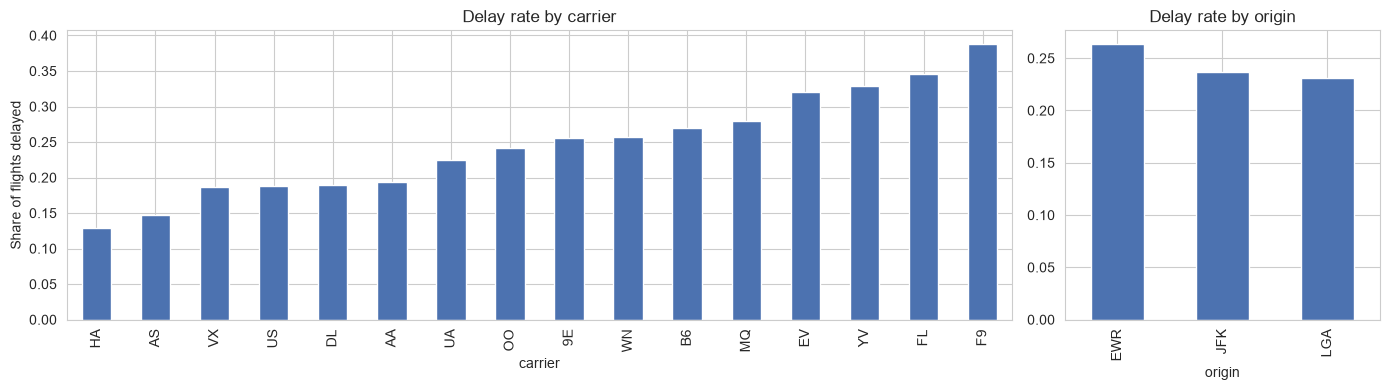

,delay_rate,flights
carrier,,
HA,0.129,342
AS,0.147,709
VX,0.187,5116
US,0.188,19831
DL,0.190,47658
AA,0.194,31947
UA,0.225,57782
OO,0.241,29
9E,0.256,17294


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1]})

carrier_stats = df.groupby("carrier")["delayed"].agg(["mean", "size"]).sort_values("mean")
carrier_stats["mean"].plot(kind="bar", ax=axes[0], color="#4C72B0")
axes[0].set_title("Delay rate by carrier")
axes[0].set_ylabel("Share of flights delayed")

df.groupby("origin")["delayed"].mean().plot(kind="bar", ax=axes[1], color="#4C72B0")
axes[1].set_title("Delay rate by origin")

plt.tight_layout()
plt.savefig("figures/delay_by_carrier_origin.png", dpi=150)
plt.show()

carrier_stats.rename(columns={"mean": "delay_rate", "size": "flights"}).round(3)

- Carriers differ a lot: F9, FL, YV and EV are delayed far more often than HA, AS, VX and US.
- **EWR** (Newark) has the highest delay rate of the three airports.

These patterns suggest **carrier, airport and time of day** are useful features.

## 4. Removing data leakage

We make the prediction **before the flight departs** (for example, on the morning of the flight day).
Any column that is only known *after* departure would leak the answer into the model and give unrealistically good
results, so it must be removed:

| Column | Why it is removed |
|--------|-------------------|
| `dep_time`, `dep_delay` | Actual departure — only known once the plane leaves |
| `arr_time`, `arr_delay` | Actual arrival — this *is* the answer (`arr_delay` was only used to build the target) |
| `air_time` | Actual flight time — only known after landing |
| `tailnum` | The plane can be swapped at the last minute; also has ~4,000 unique values |
| `flight` | Just an ID number, no meaning as a number |
| `time_hour`, `year`, `day`, `hour`, `minute` | Duplicates of other date/time columns (and `year` is always 2013) |

In [9]:
leaky_columns = ["dep_time", "dep_delay", "arr_time", "arr_delay", "air_time"]
other_dropped = ["tailnum", "flight", "time_hour", "year", "day", "hour", "minute"]

df = df.drop(columns=leaky_columns + other_dropped)
df.columns.tolist()

['month',
 'sched_dep_time',
 'sched_arr_time',
 'carrier',
 'origin',
 'dest',
 'distance',
 'delayed',
 'date',
 'day_of_week',
 'dep_hour']

## 5. Feature engineering

All features are built from the **flight schedule** or from **past days only**.

**5.1 Calendar and schedule features**
- `day_of_week`, `is_weekend`
- `dep_hour`, `arr_hour` — scheduled departure and arrival hour

We do **not** use `month` as a feature: with a date-based split the test months (Nov–Dec) never appear in training,
so the model could not learn anything useful from them.

In [10]:
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)
df["arr_hour"] = df["sched_arr_time"] // 100

**5.2 Airport congestion features** (known from the schedule in advance)
- `origin_hour_flights` — how many flights are scheduled to leave the same airport in the same hour
- `origin_day_flights` — how many flights are scheduled to leave the same airport on that day

We count these on the **full schedule** (the original `flights` table, *including* flights that were later
cancelled). Before departure, a flight that will be cancelled is still on the schedule. Counting only the flights
that actually flew would leak information: bad-weather days have many cancellations, so the count would secretly
tell the model about the weather.

In [11]:
schedule = flights.copy()
schedule["date"] = pd.to_datetime(schedule[["year", "month", "day"]])
schedule["dep_hour"] = schedule["sched_dep_time"] // 100

hour_counts = schedule.groupby(["date", "origin", "dep_hour"]).size().rename("origin_hour_flights")
day_counts = schedule.groupby(["date", "origin"]).size().rename("origin_day_flights")

df = df.join(hour_counts, on=["date", "origin", "dep_hour"]).join(day_counts, on=["date", "origin"])

df[["origin_hour_flights", "origin_day_flights"]].describe().round(1)

,origin_hour_flights,origin_day_flights
count,327346.0,327346.0
mean,20.5,312.6
std,5.9,36.6
min,1.0,171.0
25%,17.0,297.0
50%,21.0,313.0
75%,24.0,340.0
max,38.0,377.0


**5.3 Historical delay features**

How delayed has this carrier / airport / destination been **recently**? For each one we compute the share of delayed
flights over the **previous 7 calendar days**.

We build a table with one row per day and one column per carrier (or airport), holding the number of delayed flights
and the number of flights. A 7-day rolling sum, shifted by one day (`shift(1)`), means a flight on day *d* only sees
days *d-7 ... d-1* — never its own day or the future.

In [12]:
def add_past_delay_rate(df, col, window=7):
    """Share of delayed flights for each value of `col` over the previous `window` days (today excluded)."""
    delayed_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="sum", fill_value=0)
    flights_per_day = df.pivot_table(index="date", columns=col, values="delayed", aggfunc="count", fill_value=0)

    past_delayed = delayed_per_day.rolling(window, min_periods=1).sum().shift(1)
    past_flights = flights_per_day.rolling(window, min_periods=1).sum().shift(1)
    rate = past_delayed / past_flights.replace(0, np.nan)   # NaN if there were no flights in the window

    new_col = f"{col}_delay_rate_7d"
    rate = rate.stack().rename(new_col).reset_index()
    return df.merge(rate, on=["date", col], how="left")

for col in ["carrier", "origin", "dest"]:
    df = add_past_delay_rate(df, col)

df[["date", "carrier", "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]].head()

,date,carrier,carrier_delay_rate_7d,origin_delay_rate_7d,dest_delay_rate_7d
0,2013-01-01,UA,NaN,NaN,NaN
1,2013-01-01,UA,NaN,NaN,NaN
2,2013-01-01,AA,NaN,NaN,NaN
3,2013-01-01,B6,NaN,NaN,NaN
4,2013-01-01,DL,NaN,NaN,NaN


The first day of the year (and destinations with no flights in the previous week) have no history, so these values are `NaN`. We fill them
after the split using the **training-set average**, so no test information is used.

In [13]:
# Final feature list
numeric_features = ["day_of_week", "is_weekend", "dep_hour", "arr_hour", "distance",
                    "origin_hour_flights", "origin_day_flights",
                    "carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]
categorical_features = ["carrier", "origin", "dest"]

# Sanity check: no leaky column is used as a feature
assert not set(leaky_columns) & set(numeric_features + categorical_features)

df[numeric_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
day_of_week,327346.0,2.90,1.99,0.00,1.00,3.00,5.00,6.00
is_weekend,327346.0,0.25,0.44,0.00,0.00,0.00,1.00,1.00
dep_hour,327346.0,13.14,4.66,5.00,9.00,13.00,17.00,23.00
arr_hour,327346.0,15.04,4.97,0.00,11.00,15.00,19.00,23.00
distance,327346.0,1048.37,735.91,80.00,509.00,888.00,1389.00,4983.00
origin_hour_flights,327346.0,20.50,5.93,1.00,17.00,21.00,24.00,38.00
origin_day_flights,327346.0,312.64,36.58,171.00,297.00,313.00,340.00,377.00
carrier_delay_rate_7d,326508.0,0.25,0.11,0.00,0.16,0.23,0.31,1.00
origin_delay_rate_7d,326515.0,0.25,0.09,0.06,0.18,0.24,0.30,0.55
dest_delay_rate_7d,326454.0,0.25,0.12,0.00,0.16,0.23,0.32,1.00


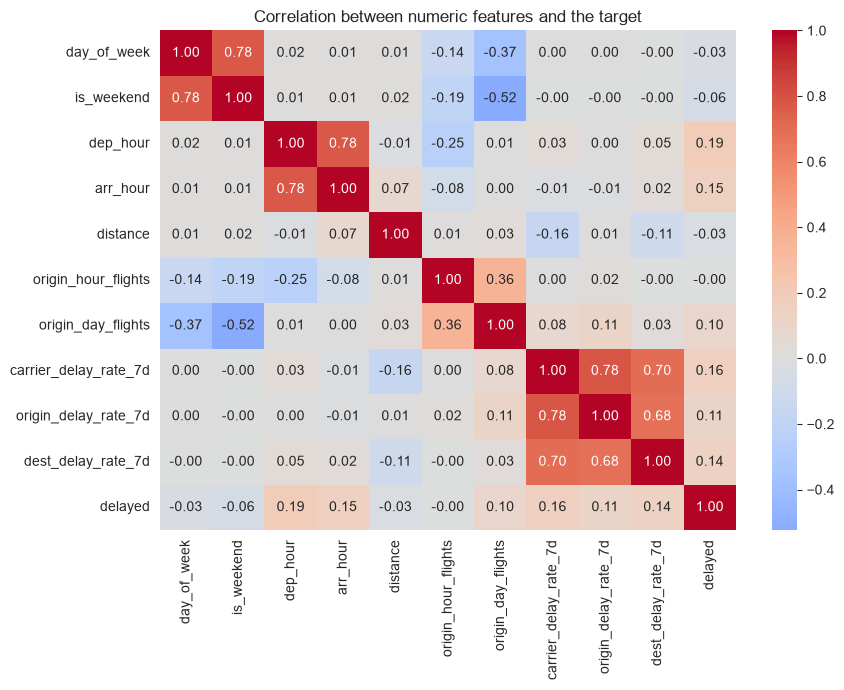

In [14]:
corr = df[numeric_features + ["delayed"]].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features and the target")
plt.tight_layout()
plt.savefig("figures/correlation.png", dpi=150)
plt.show()

- `dep_hour` and `arr_hour` are strongly correlated with each other (as expected) and have the highest correlation
  with `delayed` among the schedule features.
- The past delay rates are positively correlated with `delayed`: if a carrier or airport has been delayed recently,
  it tends to stay delayed.
- Busier days (`origin_day_flights`) are slightly more often delayed (correlation ≈ 0.10); the hourly count has almost
  no linear correlation, but it may still help tree models through interactions (e.g. a busy hour at a specific airport).
- All correlations are small (below 0.2): a single feature cannot predict delays well, which is why we combine them.

## 6. Train / validation / test split by date

Flights are ordered in time, so we **split by date instead of randomly**. A random split would let the model train on
flights from the same days it is tested on, which is not possible in real life (we cannot see the future).

| Set | Months | Used for |
|-----|--------|----------|
| Train | Jan – Aug | Fitting the models |
| Validation | Sep – Oct | Tuning (together with train, see 7.2) and calibrating probabilities |
| Test | Nov – Dec | Final evaluation, used only once |

In [15]:
train = df[df["month"] <= 8]
val = df[df["month"].isin([9, 10])]
test = df[df["month"] >= 11]

# Sanity check: the sets do not overlap in time
assert train["date"].max() < val["date"].min() and val["date"].max() < test["date"].min()

pd.DataFrame({
    "flights": [len(train), len(val), len(test)],
    "delayed_share": [train["delayed"].mean(), val["delayed"].mean(), test["delayed"].mean()],
}, index=["train", "validation", "test"]).round(3)

,flights,delayed_share
train,217727,0.264
validation,55628,0.157
test,53991,0.258


Note that the validation months (Sep–Oct) have far fewer delays than the test months (Nov–Dec). This is the real
seasonal pattern from the EDA, and it makes the test a realistic, slightly harder check.

Next we turn the categorical columns into one-hot (dummy) columns and fill the missing history values.

In [16]:
def make_features(data):
    X = pd.get_dummies(data[numeric_features + categorical_features], columns=categorical_features, dtype=int)
    return X

X_train = make_features(train)
# Validation/test must have exactly the same columns as training (unseen destinations become all zeros)
X_val = make_features(val).reindex(columns=X_train.columns, fill_value=0)
X_test = make_features(test).reindex(columns=X_train.columns, fill_value=0)

# Fill missing history values with the training average
history_cols = ["carrier_delay_rate_7d", "origin_delay_rate_7d", "dest_delay_rate_7d"]
train_means = X_train[history_cols].mean()
X_train = X_train.fillna(train_means)
X_val = X_val.fillna(train_means)
X_test = X_test.fillna(train_means)

y_train, y_val, y_test = train["delayed"], val["delayed"], test["delayed"]

print("X_train:", X_train.shape, " X_val:", X_val.shape, " X_test:", X_test.shape)

X_train: (217727, 131)  X_val: (55628, 131)  X_test: (53991, 131)


## 7. Models

### 7.1 Logistic Regression (baseline)

Logistic Regression models the probability of a delay as

$$P(\text{delayed} = 1 \mid x) = \sigma(w^\top x + b) = \frac{1}{1 + e^{-(w^\top x + b)}}$$

and learns $w, b$ by minimising the log loss with L2 regularisation. It is simple, fast and easy to interpret, so it
is a good baseline.

- Features are **standardised** (mean 0, std 1) so that the regularisation treats all features equally.
- `class_weight="balanced"` gives the delayed class more weight, because it is the minority class.

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score

log_reg = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000),
)
log_reg.fit(X_train, y_train)

val_prob_lr = log_reg.predict_proba(X_val)[:, 1]
print("Logistic Regression - validation PR AUC:", round(average_precision_score(y_val, val_prob_lr), 4))
print("Logistic Regression - validation ROC AUC:", round(roc_auc_score(y_val, val_prob_lr), 4))

Logistic Regression - validation PR AUC: 0.2548
Logistic Regression - validation ROC AUC: 0.6587


### 7.2 XGBoost

XGBoost is a **gradient boosting** model: it builds many small decision trees one after another, and each new tree
is trained to fix the mistakes (the gradient of the loss) of the trees before it. The final prediction is the sum of
all trees. Unlike Logistic Regression it can learn **non-linear patterns and interactions** (e.g. "carrier EV in the
evening at EWR").

Settings:
- `scale_pos_weight` = (number of on-time flights) / (number of delayed flights) — handles the class imbalance.
- `learning_rate=0.05`, `subsample`, `colsample_bytree`, `min_child_weight` — regularisation, to stop the trees from overfitting.

**Choosing the tree depth and number of trees.** Delay patterns change with the season, so a single validation
period (Sep–Oct, a very calm period) is a noisy guide. Instead we use **expanding-window time-series validation**:
we train on the past and validate on the next two months, three times, and average the PR AUC:

| Fold | Train on | Validate on |
|------|----------|-------------|
| 1 | Jan – Apr | May – Jun |
| 2 | Jan – Jun | Jul – Aug |
| 3 | Jan – Aug | Sep – Oct |

The test months (Nov–Dec) are never used here.

In [18]:
from xgboost import XGBClassifier

# Train + validation together, so we can cut them into time-ordered folds
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])
month_dev = pd.concat([train["month"], val["month"]])
folds = [(4, [5, 6]), (6, [7, 8]), (8, [9, 10])]   # (last training month, validation months)

def make_xgb(depth, n_trees, y):
    return XGBClassifier(
        n_estimators=n_trees,
        learning_rate=0.05,
        max_depth=depth,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=50,
        scale_pos_weight=(y == 0).sum() / (y == 1).sum(),
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

results = []
for depth in [3, 4, 6]:
    for n_trees in [100, 300]:
        scores = []
        for last_month, val_months in folds:
            fit_rows = (month_dev <= last_month).values
            val_rows = month_dev.isin(val_months).values
            model = make_xgb(depth, n_trees, y_dev[fit_rows]).fit(X_dev[fit_rows], y_dev[fit_rows])
            scores.append(average_precision_score(y_dev[val_rows], model.predict_proba(X_dev[val_rows])[:, 1]))
        results.append({"max_depth": depth, "n_trees": n_trees,
                        "fold1": scores[0], "fold2": scores[1], "fold3": scores[2], "mean_PR_AUC": np.mean(scores)})

cv_results = pd.DataFrame(results).round(4).sort_values("mean_PR_AUC", ascending=False)
cv_results

,max_depth,n_trees,fold1,fold2,fold3,mean_PR_AUC
0,3,100,0.4291,0.4521,0.2574,0.3795
2,4,100,0.4216,0.4553,0.2533,0.3767
1,3,300,0.4202,0.4489,0.2555,0.3748
4,6,100,0.4199,0.4507,0.2460,0.3722
3,4,300,0.4127,0.4528,0.2397,0.3684
5,6,300,0.4174,0.4465,0.2370,0.3670


Smaller models (shallow trees, fewer trees) generalise best to future months: bigger models start to memorise
patterns of the training months that do not repeat later. We train the final XGBoost on the training set with the
best settings. The validation set is then used for calibration.

In [19]:
best = cv_results.iloc[0]
print("Best settings: max_depth =", int(best["max_depth"]), " n_trees =", int(best["n_trees"]))

xgb = make_xgb(int(best["max_depth"]), int(best["n_trees"]), y_train).fit(X_train, y_train)

val_prob_xgb = xgb.predict_proba(X_val)[:, 1]
print("XGBoost - validation PR AUC:", round(average_precision_score(y_val, val_prob_xgb), 4))
print("XGBoost - validation ROC AUC:", round(roc_auc_score(y_val, val_prob_xgb), 4))

Best settings: max_depth = 3  n_trees = 100


XGBoost - validation PR AUC: 0.2574
XGBoost - validation ROC AUC: 0.6633


## 8. Evaluation on the test set

The test set (Nov–Dec) is used **only here**. We report:
- **PR AUC** (average precision) — the main metric. It focuses on the delayed class and is not inflated by the many
  on-time flights. A random model scores about the delay rate (~0.26 on the test set).
- **ROC AUC** — the probability that a random delayed flight gets a higher score than a random on-time flight (0.5 = random).
- **Recall at precision ≥ 0.5** — an operational view: if we only want alerts where at least half are real delays,
  what share of all delayed flights do we catch?
- **Brier score** — the mean squared error of the predicted probabilities (lower is better); measures calibration.

In [20]:
from sklearn.metrics import precision_recall_curve, roc_curve, brier_score_loss

test_prob_lr = log_reg.predict_proba(X_test)[:, 1]
test_prob_xgb = xgb.predict_proba(X_test)[:, 1]

def recall_at_precision(y_true, prob, min_precision=0.5):
    precision, recall, _ = precision_recall_curve(y_true, prob)
    return recall[precision >= min_precision].max()

def evaluate(name, y_true, prob):
    return {
        "model": name,
        "PR_AUC": average_precision_score(y_true, prob),
        "ROC_AUC": roc_auc_score(y_true, prob),
        "recall@precision0.5": recall_at_precision(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
    }

baseline_rate = y_test.mean()
results_table = pd.DataFrame([
    {"model": "Random guess", "PR_AUC": baseline_rate, "ROC_AUC": 0.5, "recall@precision0.5": np.nan, "Brier": np.nan},
    evaluate("Logistic Regression", y_test, test_prob_lr),
    evaluate("XGBoost", y_test, test_prob_xgb),
]).set_index("model").round(4)
results_table

,PR_AUC,ROC_AUC,recall@precision0.5,Brier
model,,,,
Random guess,0.2583,0.5000,NaN,NaN
Logistic Regression,0.3785,0.6482,0.0589,0.2277
XGBoost,0.3856,0.6529,0.1051,0.2198


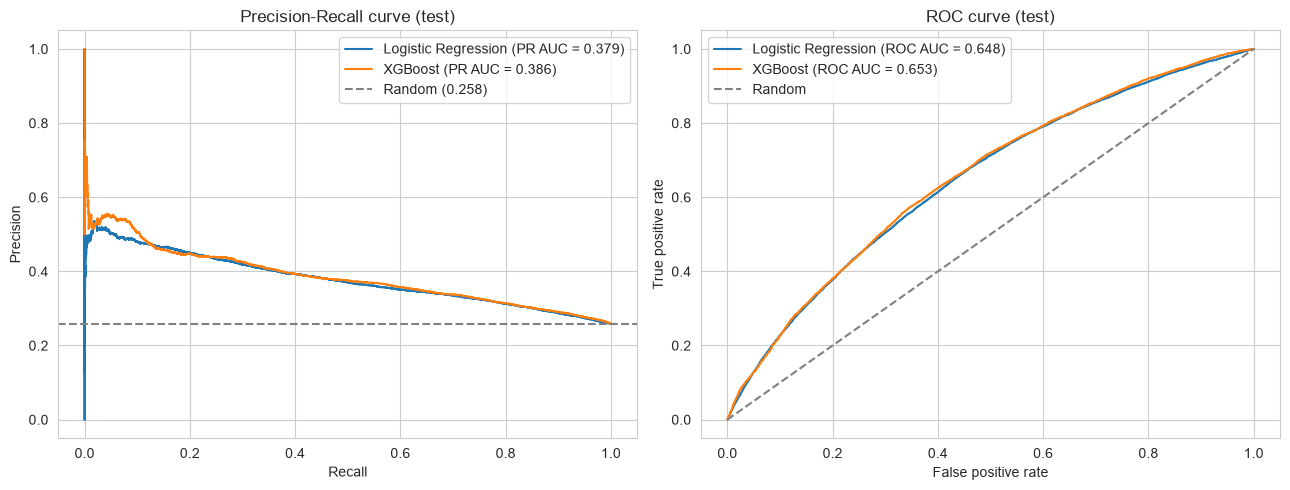

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, prob in [("Logistic Regression", test_prob_lr), ("XGBoost", test_prob_xgb)]:
    precision, recall, _ = precision_recall_curve(y_test, prob)
    axes[0].plot(recall, precision, label=f"{name} (PR AUC = {average_precision_score(y_test, prob):.3f})")
    fpr, tpr, _ = roc_curve(y_test, prob)
    axes[1].plot(fpr, tpr, label=f"{name} (ROC AUC = {roc_auc_score(y_test, prob):.3f})")

axes[0].axhline(baseline_rate, color="grey", linestyle="--", label=f"Random ({baseline_rate:.3f})")
axes[0].set_xlabel("Recall"); axes[0].set_ylabel("Precision"); axes[0].set_title("Precision-Recall curve (test)")
axes[0].legend()
axes[1].plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate"); axes[1].set_title("ROC curve (test)")
axes[1].legend()

plt.tight_layout()
plt.savefig("figures/pr_roc_curves.png", dpi=150)
plt.show()

### 8.1 Calibration

A model is **calibrated** if, among flights it gives a 30% delay probability, about 30% are actually delayed. This matters
if an airline wants to use the probability directly (e.g. to plan spare crews).

Because we used class weights, both models **over-estimate** the delay probability. We fix this with
**isotonic regression**: a simple, monotone mapping from the model's score to a calibrated probability, fitted on the
**validation set** and then applied to the test set.

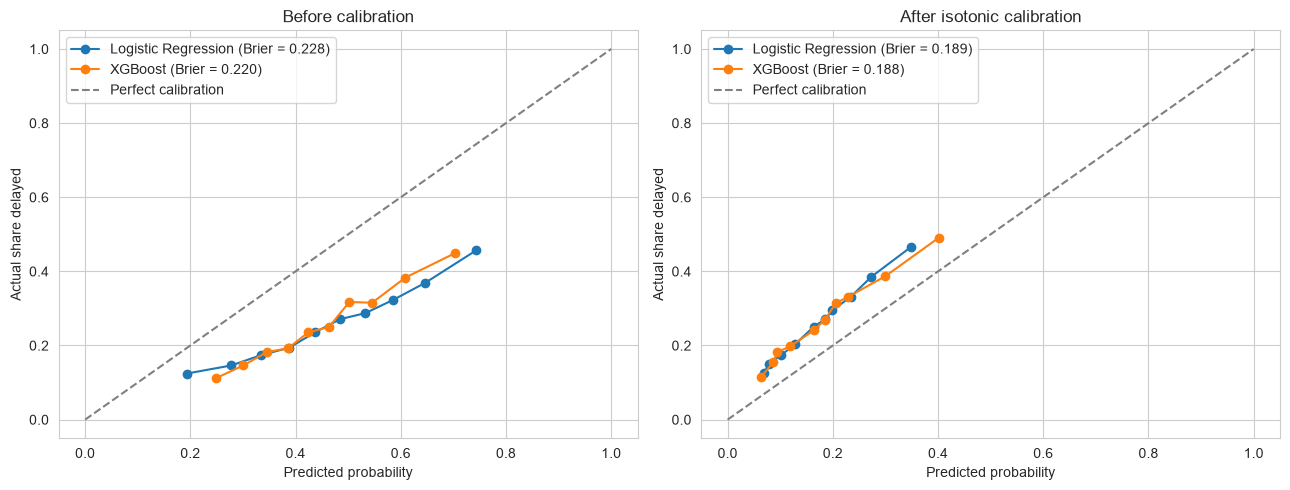

,Brier before,Brier after
Logistic Regression,0.2277,0.1893
XGBoost,0.2198,0.1879


In [22]:
from sklearn.isotonic import IsotonicRegression
from sklearn.calibration import calibration_curve

iso_lr = IsotonicRegression(out_of_bounds="clip").fit(val_prob_lr, y_val)
iso_xgb = IsotonicRegression(out_of_bounds="clip").fit(val_prob_xgb, y_val)
test_prob_lr_cal = iso_lr.predict(test_prob_lr)
test_prob_xgb_cal = iso_xgb.predict(test_prob_xgb)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, title, curves in [
    (axes[0], "Before calibration", [("Logistic Regression", test_prob_lr), ("XGBoost", test_prob_xgb)]),
    (axes[1], "After isotonic calibration", [("Logistic Regression", test_prob_lr_cal), ("XGBoost", test_prob_xgb_cal)]),
]:
    for name, prob in curves:
        frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10, strategy="quantile")
        ax.plot(mean_pred, frac_pos, marker="o", label=f"{name} (Brier = {brier_score_loss(y_test, prob):.3f})")
    ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Perfect calibration")
    ax.set_xlabel("Predicted probability"); ax.set_ylabel("Actual share delayed"); ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.savefig("figures/calibration.png", dpi=150)
plt.show()

pd.DataFrame({
    "Brier before": [brier_score_loss(y_test, test_prob_lr), brier_score_loss(y_test, test_prob_xgb)],
    "Brier after": [brier_score_loss(y_test, test_prob_lr_cal), brier_score_loss(y_test, test_prob_xgb_cal)],
}, index=["Logistic Regression", "XGBoost"]).round(4)

- Before calibration, both models predict probabilities that are much too high (curves below the diagonal).
- After isotonic calibration the Brier score drops clearly (0.23 → 0.19). The calibrated curve now sits slightly
  **above** the diagonal: the models slightly *under*-estimate delays, because the calibration months (Sep–Oct) had
  fewer delays than the test months (Nov–Dec) — the seasonal shift seen in the EDA.
- For reference, always predicting the average delay rate would give a Brier score of about 0.19, so the calibrated
  probabilities are honest but only somewhat sharper than the average. Pre-departure delay prediction is hard.

### 8.2 What does XGBoost rely on?

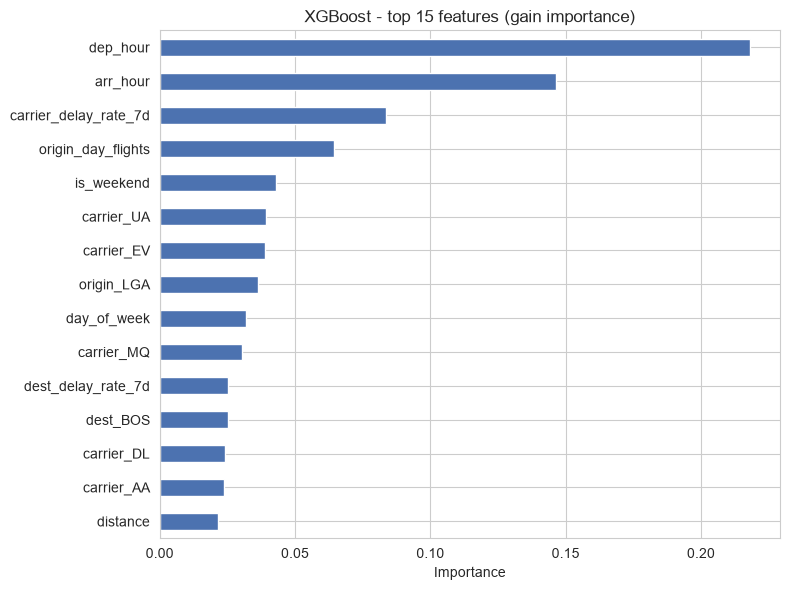

In [23]:
importance = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
importance.sort_values().plot(kind="barh", color="#4C72B0")
plt.title("XGBoost - top 15 features (gain importance)")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("figures/feature_importance.png", dpi=150)
plt.show()

In [24]:
# Largest Logistic Regression coefficients (features are standardised, so they are comparable)
coefs = pd.Series(log_reg[-1].coef_[0], index=X_train.columns)
coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3)

dep_hour                 0.508
origin_day_flights       0.300
carrier_delay_rate_7d    0.175
carrier_EV               0.142
dest_delay_rate_7d       0.103
carrier_DL              -0.101
is_weekend              -0.098
origin_EWR              -0.097
origin_LGA               0.094
day_of_week              0.077
dtype: float64

Both models agree that the **scheduled departure (and arrival) hour** is the most important feature (later flights
are more often delayed). Next come the **carrier's recent delay rate**, the **number of flights scheduled from the origin that day** (busier days
have more delays), the weekend flag and the carrier itself (e.g. UA, EV).

### 8.3 Confusion matrix at precision ≥ 0.5

To turn probabilities into yes/no alerts we need a threshold. We use the threshold where XGBoost reaches 50% precision.

Threshold: 0.693   precision: 0.500   recall: 0.105


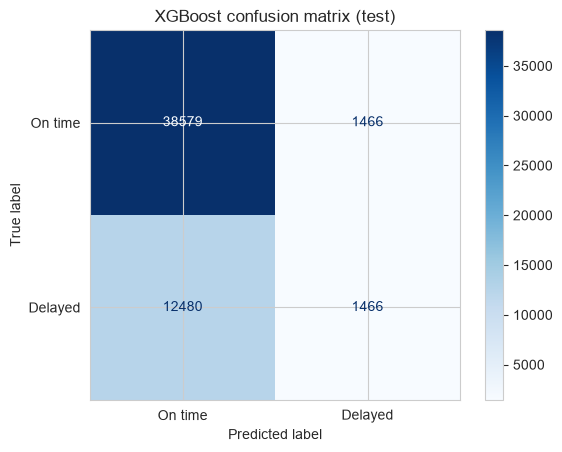

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

precision, recall, thresholds = precision_recall_curve(y_test, test_prob_xgb)
idx = np.argmax(precision[:-1] >= 0.5)       # first threshold with precision >= 0.5
threshold = thresholds[idx]
y_pred = (test_prob_xgb >= threshold).astype(int)

print(f"Threshold: {threshold:.3f}   precision: {precision[idx]:.3f}   recall: {recall[idx]:.3f}")
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["On time", "Delayed"]).plot(cmap="Blues")
plt.title("XGBoost confusion matrix (test)")
plt.savefig("figures/confusion_matrix.png", dpi=150)
plt.show()

## 9. Conclusion

**Results**
- Both models are clearly better than random guessing (PR AUC ≈ 0.26), so pre-departure information does carry a
  useful delay signal.
- **XGBoost** is the best model: PR AUC 0.386 vs 0.379 for Logistic Regression, and at 50% precision it catches
  about 11% of delayed flights vs about 6% for Logistic Regression. It can model non-linear effects and interactions
  between hour, carrier and airport.
- ROC AUC is similar for both models (≈0.65).
- Isotonic calibration on the validation set makes the predicted probabilities much more reliable (lower Brier score).
- The most important features are the **scheduled departure hour**, the **recent delay history** of the carrier and
  the **number of flights scheduled** at the origin airport that day.
- Tuning with expanding-window time-series validation picked a small model (depth 3, 100 trees); larger models did
  worse on future months.

**Limitations**
- Delays are hard to predict before departure: most delays are caused by weather, air traffic control and knock-on
  effects that are not in our features. An ROC AUC of about 0.65 is therefore expected.
- Only New York airports and only 2013; Nov–Dec (test) behaves differently from the training months (seasonality).
- No weather data was used.

**Phase 2 (Deep Learning)**
- A neural network (MLP) with **learned embeddings** for carrier, origin and destination, compared fairly against
  these ML baselines on the same date-based split and metrics.